# 04 - Scheduling with overbooking (the extension)

The no-show probabilities of notebook 02 and the service-time groups of notebook 03 decide which slots receive two patients. One clinic day of slots; each patient gets exactly one slot; a slot holds one or two patients, served shortest first. The plan minimises the expected cost of the day:

$$Z = c_I \, E[\text{idle time of the doctor}] + c_W \, E[\text{waiting time of the patients}].$$

The model is an integer linear program (ILP), written out in `utils_ilp.build_milp` with every constraint commented, and solved by `scipy.optimize.milp` (HiGHS: dual simplex for each linear relaxation, branch-and-bound on the binary variables).

## Outline
- [0 - Parameters](#0)
- [1 - The model](#1)
- [2 - Example checked by hand (Table 1 of the paper)](#2)
- [2bis - Identical slots: the pair formulation](#2bis)
- [3 - The ILP against simple policies](#3)
- [4 - Sensitivity to the load and to the costs](#4)
- [5 - Real days of the test set](#5)

In [1]:
import sys
sys.path.insert(0, "..")          # utils_ilp.py is at the root of the repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
from scipy import stats
from utils_ilp import *

<a name="0"></a>
## 0 - Parameters

Every choice of this notebook is set in the cell below, with its reason.

In [2]:
SCORES_PATH = "../data/test_scores.parquet"   # notebook 02: no-show probability of the test consultations
GROUPS_PATH = "../data/test_groups.parquet"   # notebook 03: predicted and true service-time group
RANDOM_STATE = 0

# Consultation length (minutes) of each service-time group of notebook 03. The data have no length in
# minutes (service_time is a delay in days): these are set values.
DURATION = {0: 15.0,    # short group
            1: 30.0}    # long group

# Clinic day: 4 slots of 15 minutes and 6 slots of 30 minutes (half a day of 4 hours). With two slot
# lengths the ILP also chooses which length each patient gets (with slots of one length, on the 10 %
# pilot, the ILP and the greedy policy had the same expected cost on every day).
SLOT_LENGTHS = [15.0] * 4 + [30.0] * 6

# Costs of one minute: idle doctor (c_I) and waiting patient (c_W); idle time costs twice as much.
C_I = 1.0
C_W = 0.5

# Cost of one minute of overtime (work after the end of the day). The ILP of the paper has no overtime;
# it is counted only when a day is simulated (sections 3 and 5), at the cost of idle time.
C_O = 1.0

# Order of the slots in the day. Every order has the same cost in the ILP; the order changes only the
# simulated day, where a delay carries over to the next slots. True, for the ILP and the greedy policy:
# the slots with one patient first, the double-booked slots at the end, each slot keeping its length
# (on the 10 % pilot this order gave the lowest simulated cost; double-booked slots first, the highest).
DOUBLE_BOOKED_LAST = True

N_PATIENTS = 12            # reference load: 12 patients for 10 slots (n/S = 1.2)

# Solver (scipy.optimize.milp, HiGHS): stop when proven optimal up to a relative gap of 1e-6,
# or after TIME_LIMIT seconds (reported if it happens).
TIME_LIMIT = 60.0
MIP_REL_GAP = 1e-6

N_EQUIVALENCE = 30        # small instances on which both formulations are compared (section 2bis)
N_INSTANCES = 30           # random days per experiment (sections 3 and 4)
N_SCENARIOS = 10_000       # show/no-show scenarios of the simulation (section 3)
LOADS = [1.0, 1.2, 1.5, 1.8, 2.0]       # patients per slot (section 4): 10, 12, 15, 18, 20 patients
CW_RATIOS = [0.25, 0.5, 1.0, 2.0]       # c_W / c_I (section 4)
N_TEST_DAYS = 100          # real days built from the test set (section 5)

# Table 1 of the paper (illustrative example): 7 patients, 4 slots, published optimum Z* = 65.62.
TABLE1 = dict(q=np.array([0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60]),
              s=np.array([43.0, 43.0, 43.0, 8.0, 8.0, 8.0, 8.0]),
              L=[30.0, 30.0, 60.0, 60.0], c_I=1.0, c_W=0.5, Z_paper=65.62)

<a name="1"></a>
## 1 - The model

**Data.** $n$ patients, $T$ slots; slot $t$ lasts $L_t$ minutes; patient $i$ comes with probability $q_i = 1 - p_i$ ($p_i$: no-show probability of notebook 02) and needs $s_i$ minutes.

**Variables.** $x_{it} = 1$ if patient $i$ is in slot $t$ (binary); $z_{ijt} = 1$ if patients $i<j$ share slot $t$.

**Expected cost of one slot** (closed forms, patients served shortest first):
- busy time of patient $i$ alone: $a_{it} = q_i \min(s_i, L_t)$;
- if $i$ and $j$ share the slot, the longer one waits for the shorter one when both come: $w_{ij} = q_i q_j \min(s_i, s_j)$;
- and their busy time cannot exceed $L_t$: correction $\delta_{ijt} = q_i q_j \big(\min(s_i+s_j, L_t) - \min(s_i, L_t) - \min(s_j, L_t)\big) \le 0$.

$$\min_{x,z} \; c_I \sum_t L_t \; - \; c_I \sum_{i,t} a_{it}\, x_{it} \; + \sum_{i<j,\,t} \big(c_W\, w_{ij} - c_I\, \delta_{ijt}\big)\, z_{ijt}$$

subject to
- (C1) $\sum_t x_{it} = 1$ for every patient: everyone gets exactly one slot;
- (C2) $\sum_i x_{it} \le 2$ for every slot;
- (C3) $z_{ijt} \ge x_{it} + x_{jt} - 1$, $z_{ijt} \ge 0$.

The coefficient of $z_{ijt}$ is never negative, so at the optimum $z_{ijt} = \max(0, x_{it} + x_{jt} - 1) \in \{0, 1\}$: $z$ can be declared continuous (Proposition 1). Only the $n T$ variables $x$ are binary.

**Solution method.** The *linear relaxation* (the same problem with $0 \le x \le 1$) is solved by the dual simplex method; its value is a lower bound on the optimum. *Branch-and-bound* then fixes a fractional $x_{it}$ to 0 in one branch and to 1 in the other, solves the two relaxations, and discards every branch whose bound is worse than the best planning found. It stops when the best planning is proven optimal (gap below `MIP_REL_GAP`).

<a name="2"></a>
## 2 - Example checked by hand (Table 1 of the paper)

The ILP is solved, then checked in two independent ways: by trying all $4^7$ assignments of the 7 patients to the 4 slots, and by listing, slot by slot, every show/no-show scenario of its patients.

In [3]:
t1 = TABLE1
ilp = solve_ilp(t1["q"], t1["s"], t1["L"], t1["c_I"], t1["c_W"], TIME_LIMIT, MIP_REL_GAP)
brute = solve_by_enumeration(t1["q"], t1["s"], t1["L"], t1["c_I"], t1["c_W"])
print(f"ILP          : Z* = {ilp['Z']:.4f}, proven optimal: {ilp['optimal']}, "
      f"{ilp['nodes']} branch-and-bound nodes, {ilp['seconds']:.2f} s")
print(f"Enumeration  : Z* = {brute['Z']:.4f} (all {4**7:,} assignments)")
print(f"Paper        : Z* = {t1['Z_paper']:.2f}")

rows = []
for t in range(len(t1["L"])):
    patients = sorted(ilp["planning"].get(t, []), key=lambda i: t1["s"][i])
    idle, wait = slot_cost_enumeration(patients, t1["q"], t1["s"], t1["L"][t])
    rows.append({"Slot": t, "L (min)": t1["L"][t], "Patients (SPT order)": ", ".join(map(str, patients)),
                 "E[Idle] (min)": idle, "E[Wait] (min)": wait,
                 "c_I E[Idle] + c_W E[Wait]": t1["c_I"] * idle + t1["c_W"] * wait})
table1 = pd.DataFrame(rows).set_index("Slot")
table1.loc["Total"] = ["", "", table1["E[Idle] (min)"].sum(), table1["E[Wait] (min)"].sum(),
                       table1["c_I E[Idle] + c_W E[Wait]"].sum()]
table1

ILP          : Z* = 65.6200, proven optimal: True, 5 branch-and-bound nodes, 0.17 s
Enumeration  : Z* = 65.6200 (all 16,384 assignments)
Paper        : Z* = 65.62


,L (min),Patients (SPT order),E[Idle] (min),E[Wait] (min),c_I E[Idle] + c_W E[Wait]
Slot,,,,,
0,30.0,2,6.00,0.00,6.00
1,30.0,"3, 4",18.40,4.20,20.50
2,60.0,"6, 0",16.50,4.32,18.66
3,60.0,"5, 1",18.25,4.42,20.46
Total,,,59.15,12.94,65.62


<a name="2bis"></a>
## 2bis - Identical slots: the pair formulation

In the experiments below the day has `SLOT_LENGTHS`: $n_k$ slots of each length $L_k$. Slots of the same length are interchangeable: only **who shares a slot, and the length of that slot**, matter. Every planning of the model above exists in $\prod_k n_k!$ copies of equal cost (4! 6! = 17,280 here), obtained by permuting the slots of the same length, and branch-and-bound has to rule them out one by one. With 8 identical slots and 12 patients it no longer proved the optimum within a minute.

The same problem written without slot index (`solve_pairs`): $u_{ik} = 1$ if patient $i$ is alone in a slot of length $L_k$, $y_{ijk} = 1$ if $i$ and $j$ share a slot of length $L_k$,

$$\min \; c_I \sum_t L_t - c_I \sum_{i,k} a_{ik} u_{ik} + \sum_{i<j,\,k} \big(c_W w_{ij} - c_I (a_{ik} + a_{jk} + \delta_{ijk})\big) y_{ijk}$$

subject to $\sum_k \big(u_{ik} + \sum_j y_{ijk}\big) = 1$ (every patient alone or in one pair, in one slot) and $\sum_i u_{ik} + \sum_{i<j} y_{ijk} \le n_k$ (at most $n_k$ slots of length $L_k$). The coefficients are those of section 1. Below, both formulations are solved on `N_EQUIVALENCE` small days with slots of 15 and 30 minutes: same optimum.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
rows = []
for k in range(N_EQUIVALENCE):
    n, L_small = int(rng.integers(4, 9)), [15.0, 30.0, 15.0, 30.0]
    q = rng.uniform(0.6, 0.99, n)
    s = rng.choice(list(DURATION.values()), n)
    slot_model = solve_ilp(q, s, L_small, C_I, C_W, TIME_LIMIT, MIP_REL_GAP)
    pair_model = solve_pairs(q, s, L_small, C_I, C_W, TIME_LIMIT, MIP_REL_GAP)
    rows.append({"patients": n, "slots": len(L_small), "Z slot model": slot_model["Z"], "Z pair model": pair_model["Z"],
                 "both proven optimal": slot_model["optimal"] and pair_model["optimal"],
                 "seconds slot model": slot_model["seconds"], "seconds pair model": pair_model["seconds"]})
equivalence = pd.DataFrame(rows)
print(f"Largest difference of the optimum: {np.abs(equivalence['Z slot model'] - equivalence['Z pair model']).max():.2e}; "
      f"both proven optimal on {equivalence['both proven optimal'].sum()}/{len(equivalence)} days")
equivalence.describe().loc[["mean", "max"]].round(4)

Largest difference of the optimum: 7.11e-15; both proven optimal on 30/30 days


,patients,slots,Z slot model,Z pair model,seconds slot model,seconds pair model
mean,5.8,4.0,19.7807,19.7807,0.0614,0.0044
max,8.0,4.0,37.1843,37.1843,0.1539,0.0051


<a name="3"></a>
## 3 - The ILP against simple policies

`N_INSTANCES` clinic days of `N_PATIENTS` patients for the slots `SLOT_LENGTHS`. The patients of a day are consultations of the test set drawn at random: their no-show probability comes from notebook 02, their length from their predicted service-time group (notebook 03). The ILP is solved with the pair formulation (section 2bis).

Policies compared, all judged with the same cost:
- **ILP**: the optimal planning of the model;
- **Greedy**: the $T$ patients with the largest expected busy time $q_i s_i$ get a slot each (the longest ones in the longest slots), then each remaining patient joins the single-patient slot with the largest expected idle time;
- **Single booking**: one patient per slot, in the order of the requests; the patients beyond the $T$ slots are not booked. It serves fewer patients (column *Served*) and pays nothing for the ones it turns away: its cost is not comparable as such, the comparison is a trade-off between patients served and minutes of waiting.

**Order of the slots.** With slots of equal length the ILP gives the same cost to every order of the slots, so it does not choose one. The order is set in the parameters (`DOUBLE_BOOKED_LAST`), the same for the ILP and Greedy: slots with one patient first, double-booked slots at the end, each slot keeping its length.

Two costs: the **model** cost (each slot starts on time, no overtime), and the **simulated** cost of the real day, where a late slot delays the next ones and every minute after the end of the day costs `C_O` (`N_SCENARIOS` show/no-show scenarios, the same for every policy).

In [5]:
scores = pd.read_parquet(SCORES_PATH).merge(pd.read_parquet(GROUPS_PATH), on="row", validate="one_to_one")
print(f"{len(scores):,} test consultations; mean no-show probability {scores['p_noshow'].mean():.4f}, "
      f"observed no-show rate {scores['NoShow'].mean():.4f}; predicted long group {scores['group_pred'].mean():.3f}")
L = SLOT_LENGTHS

def draw_day(rng, n):
    """n test consultations drawn at random: show probability and length from the predictions."""
    day = scores.iloc[rng.choice(len(scores), size=n, replace=False)]
    return 1 - day["p_noshow"].to_numpy(), day["group_pred"].map(DURATION).to_numpy()

def plannings(q, s, c_W):
    """Planning of each policy and the slot lengths in the order of its day: {policy: (planning, L)}."""
    ilp = solve_pairs(q, s, L, C_I, c_W, TIME_LIMIT, MIP_REL_GAP)
    order = (lambda planning: pairs_last(planning, L)) if DOUBLE_BOOKED_LAST else (lambda planning: (planning, L))
    return ilp, {"ILP": order(ilp["planning"]), "Greedy": order(greedy(q, s, L)),
                 "Single booking": (single_booking(len(q), len(L)), L)}

def paired_summary(df, cost, reference="ILP"):
    """Difference policy - ILP, day by day: mean, 95 % confidence interval, Wilcoxon signed-rank test."""
    rows = []
    for policy in df["policy"].unique():
        if policy == reference:
            continue
        diff = (df[df.policy == policy].set_index("day")[cost] - df[df.policy == reference].set_index("day")[cost])
        half = stats.t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff))
        rows.append({"Policy": policy, f"Mean difference vs {reference}": diff.mean(),
                     "95 % CI low": diff.mean() - half, "95 % CI high": diff.mean() + half,
                     f"Days where {reference} is better": f"{(diff > 1e-9).sum()}/{len(diff)}",
                     "p (Wilcoxon)": stats.wilcoxon(diff).pvalue if (diff != 0).any() else 1.0})
    return pd.DataFrame(rows).set_index("Policy")

3,402,784 test consultations; mean no-show probability 0.0311, observed no-show rate 0.0311; predicted long group 0.355


In [6]:
rng = np.random.default_rng(RANDOM_STATE)
records, status = [], []
for day in range(N_INSTANCES):
    q, s = draw_day(rng, N_PATIENTS)
    ilp, plans = plannings(q, s, C_W)
    status.append({"optimal": ilp["optimal"], "seconds": ilp["seconds"], "nodes": ilp["nodes"]})
    shows = rng.random((N_SCENARIOS, N_PATIENTS)) < q          # common random numbers
    for policy, (planning, L_day) in plans.items():
        model = planning_cost(planning, q, s, L_day, C_I, C_W)
        sim = simulate_day(planning, s, L_day, shows, C_I, C_W, C_O)
        records.append({"day": day, "policy": policy, "Z model": model["Z"], "Z simulated": sim["Z"].mean(),
                        "E[Idle] (min)": model["E_idle"], "E[Wait] (min)": model["E_wait"],
                        "Idle simulated": sim["idle"].mean(), "Wait simulated": sim["wait"].mean(),
                        "Overtime simulated": sim["overtime"].mean(),
                        "Served": sum(len(p) for p in planning.values()),
                        "Double-booked slots": sum(len(p) == 2 for p in planning.values())})
compare = pd.DataFrame(records)
status = pd.DataFrame(status)
print(f"ILP proven optimal on {status['optimal'].sum()}/{len(status)} days; "
      f"time per ILP: median {status['seconds'].median():.2f} s, max {status['seconds'].max():.2f} s")
compare.groupby("policy", sort=False).mean(numeric_only=True).drop(columns="day").round(3)

ILP proven optimal on 30/30 days; time per ILP: median 0.00 s, max 0.01 s


,Z model,Z simulated,E[Idle] (min),E[Wait] (min),Idle simulated,Wait simulated,Overtime simulated,Served,Double-booked slots
policy,,,,,,,,,
ILP,27.126,43.340,14.664,24.923,14.450,38.104,9.838,12.0,2.0
Greedy,27.407,44.632,14.746,25.322,14.460,40.645,9.849,12.0,2.0
Single booking,65.327,82.957,65.327,0.000,43.217,77.917,0.782,10.0,0.0


In [7]:
for cost in ["Z model", "Z simulated"]:
    print(cost)
    display(paired_summary(compare, cost).round(4))

Z model


,Mean difference vs ILP,95 % CI low,95 % CI high,Days where ILP is better,p (Wilcoxon)
Policy,,,,,
Greedy,0.2815,0.1221,0.4410,26/30,0.0
Single booking,38.2014,31.6137,44.7891,30/30,0.0


Z simulated


,Mean difference vs ILP,95 % CI low,95 % CI high,Days where ILP is better,p (Wilcoxon)
Policy,,,,,
Greedy,1.2919,0.0234,2.5605,26/30,0.0004
Single booking,39.6167,26.8031,52.4303,27/30,0.0000


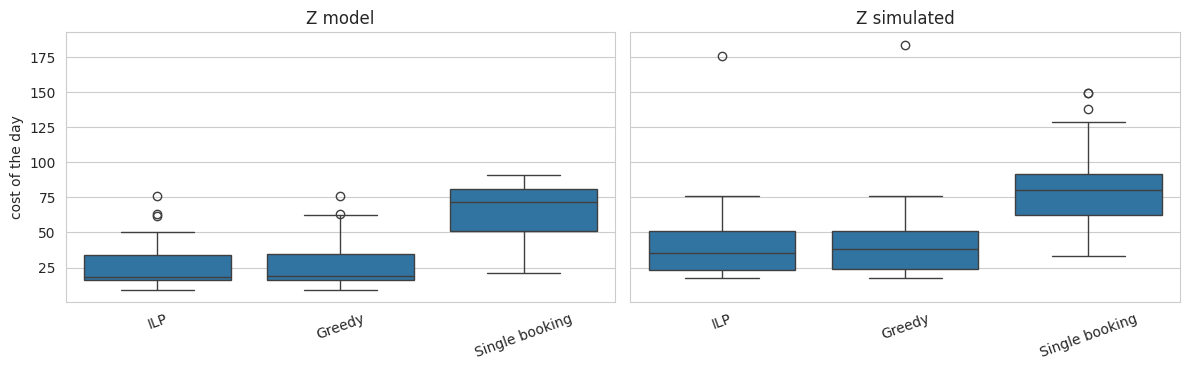

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for axis, cost in zip(ax, ["Z model", "Z simulated"]):
    sns.boxplot(data=compare, x="policy", y=cost, ax=axis)
    axis.set_title(cost); axis.set_xlabel(""); axis.set_ylabel("cost of the day")
    axis.tick_params(axis="x", labelrotation=20)
plt.tight_layout(); plt.show()

<a name="4"></a>
## 4 - Sensitivity to the load and to the costs

One factor varies at a time around the reference (`N_PATIENTS` patients, `C_W` / `C_I`); `N_INSTANCES` days per value, the same random draws for every value.

In [9]:
records = []
for factor, values in [("load", LOADS), ("cW/cI", CW_RATIOS)]:
    for value in values:
        n = round(value * len(L)) if factor == "load" else N_PATIENTS
        c_W = C_W if factor == "load" else value * C_I
        rng = np.random.default_rng(RANDOM_STATE)
        for day in range(N_INSTANCES):
            q, s = draw_day(rng, n)
            ilp, plans = plannings(q, s, c_W)
            for policy in ["ILP", "Greedy"]:
                planning, L_day = plans[policy]
                cost = planning_cost(planning, q, s, L_day, C_I, c_W)
                records.append({"factor": factor, "value": value, "day": day, "policy": policy, "Z": cost["Z"],
                                "E[Idle] (min)": cost["E_idle"], "E[Wait] (min)": cost["E_wait"],
                                "optimal": ilp["optimal"]})
sens = pd.DataFrame(records)
print(f"ILP proven optimal: {sens[sens.policy == 'ILP']['optimal'].sum()}/{(sens.policy == 'ILP').sum()}")
sens.groupby(["factor", "value", "policy"])[["Z", "E[Idle] (min)", "E[Wait] (min)"]].mean().unstack("policy").round(2)

ILP proven optimal: 270/270


Z        E[Idle] (min)        E[Wait] (min)        
policy       Greedy    ILP        Greedy    ILP        Greedy     ILP
factor value                                                         
cW/cI  0.25   20.11  19.84         13.42  13.21         26.74   26.55
       0.50   26.79  26.48         13.42  13.21         26.74   26.54
       1.00   40.16  39.65         13.42  13.41         26.74   26.24
       2.00   66.90  65.87         13.42  13.45         26.74   26.21
load   1.00   39.01  39.01         39.01  39.01          0.00    0.00
       1.20   26.79  26.48         13.42  13.21         26.74   26.54
       1.50   37.46  36.49          2.71   1.90         69.51   69.18
       1.80   57.87  56.92          1.68   0.77        112.38  112.30
       2.00   72.47  71.72          1.33   0.57        142.28  142.29

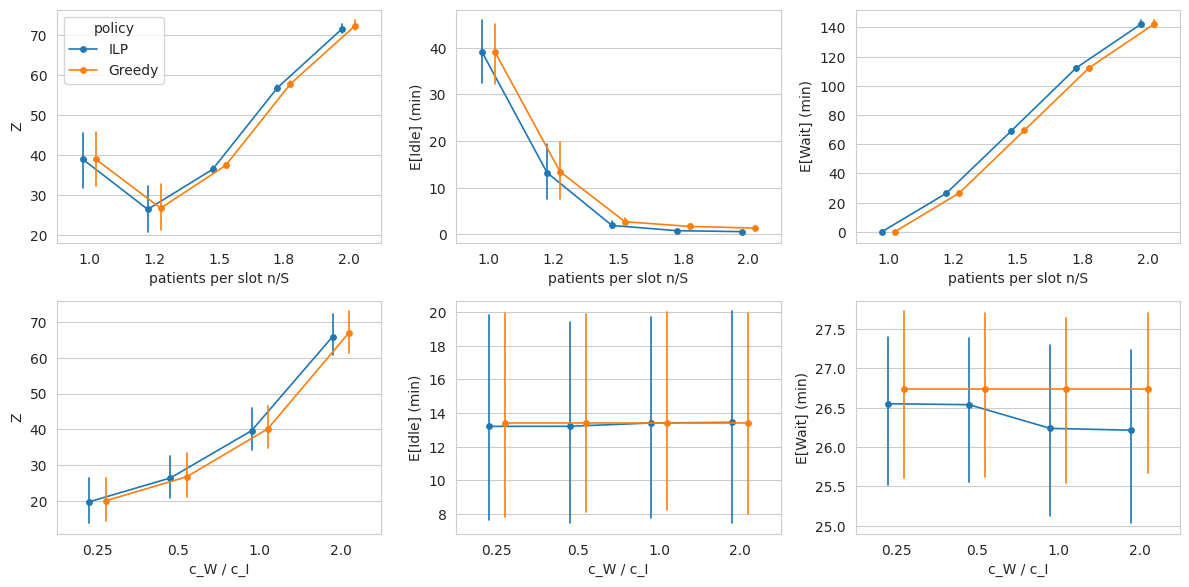

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for row, (factor, xlabel) in enumerate([("load", "patients per slot n/S"), ("cW/cI", "c_W / c_I")]):
    sub = sens[sens.factor == factor]
    for col, y in enumerate(["Z", "E[Idle] (min)", "E[Wait] (min)"]):
        sns.pointplot(data=sub, x="value", y=y, hue="policy", errorbar=("ci", 95), ax=ax[row, col],
                      markersize=4, linewidth=1.2, dodge=0.2)
        ax[row, col].set_xlabel(xlabel)
        if (row, col) != (0, 0):
            ax[row, col].get_legend().remove()
plt.tight_layout(); plt.show()

<a name="5"></a>
## 5 - Real days of the test set

`N_TEST_DAYS` days of `N_PATIENTS` test consultations, drawn without replacement. Each policy plans the day with the **predicted** probabilities and groups; the day is then judged on what **actually happened**: who did not show up, and the length of the true group of each consultation, with delays carried over from slot to slot and overtime counted at `C_O`.

In [11]:
rng = np.random.default_rng(RANDOM_STATE + 1)
rows = rng.choice(len(scores), size=N_TEST_DAYS * N_PATIENTS, replace=False)
records = []
for day in range(N_TEST_DAYS):
    sample = scores.iloc[rows[day * N_PATIENTS:(day + 1) * N_PATIENTS]]
    q = 1 - sample["p_noshow"].to_numpy()
    s = sample["group_pred"].map(DURATION).to_numpy()            # planned with the predicted group
    s_true = sample["group_true"].map(DURATION).to_numpy()       # judged with the true group
    came = (sample["NoShow"].to_numpy() == 0)[None, :]           # one scenario: the real one
    ilp, plans = plannings(q, s, C_W)
    for policy, (planning, L_day) in plans.items():
        real = simulate_day(planning, s_true, L_day, came, C_I, C_W, C_O)
        records.append({"day": day, "policy": policy, "Z realised": real["Z"][0],
                        "Idle (min)": real["idle"][0], "Wait (min)": real["wait"][0],
                        "Overtime (min)": real["overtime"][0],
                        "Served": sum(len(p) for p in planning.values()), "no-shows": int((~came).sum())})
real_days = pd.DataFrame(records)
print(f"{N_TEST_DAYS} days, {real_days.drop_duplicates('day')['no-shows'].sum()} no-shows among "
      f"{N_TEST_DAYS * N_PATIENTS} consultations")
display(real_days.groupby("policy", sort=False).mean(numeric_only=True).drop(columns="day").round(3))
paired_summary(real_days, "Z realised").round(4)

100 days, 41 no-shows among 1200 consultations


,Z realised,Idle (min),Wait (min),Overtime (min),Served,no-shows
policy,,,,,,
ILP,83.925,26.25,86.25,14.55,12.0,0.41
Greedy,84.525,25.50,90.45,13.80,12.0,0.41
Single booking,77.925,49.20,57.45,0.00,10.0,0.41


,Mean difference vs ILP,95 % CI low,95 % CI high,Days where ILP is better,p (Wilcoxon)
Policy,,,,,
Greedy,0.6,-4.8368,6.0368,38/100,0.6682
Single booking,-6.0,-14.6464,2.6464,44/100,0.3929
